# ADS Project — Data Cleaning & Exploratory Data Analysis (EDA)
## Construction Permit Timelines in San Francisco
**Dataset + Hypothesis 4: Application Volume and Time Trends**

**Research question:** Do months with more filed applications have lower percentages of permits issued within 365 days?

## 1. Import libraries and load CSV from Google Drive
Mount Google Drive and read `construction_permits_ssot.csv` from **MyDrive / Colab Notebooks**. No manual CSV upload is needed.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11})

FILE = Path("/content/drive/MyDrive/Colab Notebooks/construction_permits_ssot.csv")
if not FILE.exists():
    raise FileNotFoundError(f"CSV not found at {FILE}. Check the folder and filename in Google Drive.")
df = pd.read_csv(FILE, low_memory=False)
print("Rows:", len(df), "| Columns:", len(df.columns))
display(df.head())


Mounted at /content/drive
Rows: 154689 | Columns: 95


,permit_number,permit_type,permit_type_definition,permit_creation_date,block,lot,street_number,street_number_suffix,street_name,street_suffix,...,invalid_issuance_chronology,has_recorded_issuance,observed_at_least_365_days,issued_within_365_days,building_age_at_filing,building_age_group,estimated_cost_2024_usd_cpi,estimate_revision_usd,estimate_revision_pct,snapshot_date_utc
0,201806081423,8,otc alterations permit,2018-06-08T00:00:00.000,1139,005,167,NaN,Stanyan,Bl,...,True,True,True,NaN,82.0,60-99 years,4910.057341,0.0,0.000000,2026-10-22
1,201812067576,3,additions alterations or repairs,2018-12-06T00:00:00.000,2822A,035,85,NaN,Midcrest,Wy,...,False,True,True,True,57.0,30-59 years,186933.181573,0.0,0.000000,2026-10-22
2,201901029418,8,otc alterations permit,2019-01-02T00:00:00.000,0492,012,2036,NaN,Lombard,St,...,False,True,True,True,60.0,60-99 years,10592.880289,500.0,5.882353,2026-10-22
3,201901029420,8,otc alterations permit,2019-01-02T00:00:00.000,5656,036,69,NaN,Nebraska,St,...,False,True,True,True,49.0,30-59 years,13085.322710,0.0,0.000000,2026-10-22
4,201901029419,8,otc alterations permit,2019-01-02T00:00:00.000,3713,007,1,NaN,Market,St,...,False,True,True,True,40.0,30-59 years,790.104247,0.0,0.000000,2026-10-22


## 2. Understand the structure
Look at column names, types, and basic counts **before** changing anything.

In [2]:
print('Column names:')
print(df.columns.tolist())
print('Data types:')
print(df.dtypes.value_counts())
print('Number of unique permit records:', df['record_id'].nunique())
display(df[['permit_number', 'record_id', 'filed_date', 'issued_date',
            'permit_type', 'issued_within_365_days']].head())

Column names:
['permit_number', 'permit_type', 'permit_type_definition', 'permit_creation_date', 'block', 'lot', 'street_number', 'street_number_suffix', 'street_name', 'street_suffix', 'unit', 'unit_suffix', 'description', 'primary_priority', 'all_priority_types', 'status', 'status_date', 'filed_date', 'issued_date', 'completed_date', 'first_construction_document_date', 'approved_date', 'structural_notification', 'number_of_existing_stories', 'number_of_proposed_stories', 'voluntary_soft_story_retrofit', 'fire_only_permit', 'estimated_cost', 'revised_cost', 'existing_use', 'existing_units', 'proposed_use', 'proposed_units', 'plansets', 'tidf_compliance', 'existing_occupancy', 'proposed_occupancy', 'existing_construction_type', 'existing_construction_type_description', 'proposed_construction_type', 'proposed_construction_type_description', 'site_permit', 'last_permit_activity_date', 'application_submission_method', 'adu', 'primary_address_flag', 'supervisor_district', 'neighborhoods_an

,permit_number,record_id,filed_date,issued_date,permit_type,issued_within_365_days
0,201806081423,1526876506023,2019-04-24T09:55:02.000,2018-10-05T09:12:53.000,8,NaN
1,201812067576,1534074145041,2019-01-18T10:48:20.000,2020-01-16T12:25:11.000,3,True
2,201901029418,1536597399219,2019-01-02T07:32:36.000,2019-01-14T09:06:48.000,8,True
3,201901029420,1536598185994,2019-01-02T07:35:15.000,2019-01-02T07:39:17.000,8,True
4,201901029419,1536599164605,2019-01-02T07:34:29.000,2019-01-02T08:22:45.000,8,True


## 2A. Detailed dataset summary — `dfSummary()`
This report provides a compact overview of selected columns **before cleaning**: data types, missing values, frequency distributions and mini charts. The original dataset has 95 columns; the report deliberately focuses on 12 relevant columns.


In [3]:
# Install once per Colab runtime
%pip -q install summarytools

from summarytools import dfSummary
from IPython.display import display

summary_cols = [
    'permit_number', 'permit_type', 'permit_type_definition', 'status',
    'filed_date', 'issued_date', 'approved_date', 'completed_date',
    'filing_to_issuance_days', 'observed_at_least_365_days',
    'issued_within_365_days', 'invalid_issuance_chronology'
]
summary_cols = [col for col in summary_cols if col in df.columns]
summary_df = df[summary_cols].copy()

# summarytools may not support pandas' newer StringDtype
for col in summary_df.select_dtypes(include='string').columns:
    summary_df[col] = summary_df[col].astype(object)

print(f'Original dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Summary report: {summary_df.shape[0]:,} rows x {summary_df.shape[1]} selected columns')
display(dfSummary(summary_df))


Original dataset: 154,689 rows x 95 columns
Summary report: 154,689 rows x 12 selected columns


No,Variable,Stats / Values,Freqs / (% of Valid),Graph,Missing
1,permit_number[object],1. 2004031889662. 2024081385633. 2024040290754. 2024112758435. 2024110745556. 2024120963737. 2024112255698. 2024111550879. 20240722697710. 20241015289211. other,"1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)154,679 (100.0%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAJsAAAD+CAYAAAAtWHdlAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjAsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvlHJYcgAAAAlwSFlzAAAPYQAAD2EBqD+naQAAAy5JREFUeJzt3MGN02AURtHnKIJhY2tkKSVADymCLb3ThTcwrMKCHq4lc04F/+JKT5H8ZXm9XgOF29kP4P8hNjJiIyM2MmIjIzYyYiMjNjJiIyM2MrdlWb4ty/J29kO4vtvMfJ2Zz2c/hOtzRsmIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNzG1mfs7Mn7MfwvUt/sWIijNKRmxkrKvIWFeRcUbJiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MgYvJAxeCHjjJIRGxmDFzIGL2ScUTJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MgYvZAxeyDijZMRGRmxkrKvIWFeRcUbJiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MhYV5GxriLjjJIRGxmDFzIGL2ScUTJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MgYvZAxeyDijZMRGxuCFjMELGWeUjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MhYV5GxriLjjJIRGxnrKjLWVWScUTJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MgYvZAxeyDijZMRGxuCFjMELGWeUjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2MwQsZgxcyzigZsZERGxnrKjLWVWScUTJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MtZVZKyryDijZMRGxuCFjMELGWeUjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2MwQsZgxcyziiZZWa+zMynsx/C9d33ff++ruv72Q/h+u7rur4/n8/f27Z9nP0Yrus4jrf7zMy2bR+Px+PX2Q/i2vxAICM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiI3Of+ff5x9kP4dqO43hb9n3/4eNJCj4LJ2NdRcYPBDJiIyM2MmIjIzYyYiMjNjJiIyM2Mn8BY+dLgsx6ZCoAAAAASUVORK5CYII="">",0(0.0%)
2,permit_type[int64],1. 82. 33. 44. 25. 66. 77. 18. 5,"140,743 (91.0%)9,529 (6.2%)2,666 (1.7%)513 (0.3%)480 (0.3%)416 (0.3%)291 (0.2%)51 (0.0%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAJsAAAC4CAYAAAD0WZ4UAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjAsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvlHJYcgAAAAlwSFlzAAAPYQAAD2EBqD+naQAAAxFJREFUeJzt3UFuWlcAhtH7EEqbCQgheQntHlhEFptFsIjuwbL8BnWaCR3EVE1HBvd9KOScmQdId/CJa9D77el0Og0orG59AH4eYiMjNjJiIyM2MmIjM40xPo4xPtz6IPxQvp5Op5dLX7Te7/efNpvNbokTcZ/meX6apunzpcGtN5vN7nA4vGy32y9LHY778fz8/OvxeNw9Pj5+GGNcFtsYY2y32y8PDw9/LnI67tHHa17kAwIZsZERGxmxkREbGbGRERsZsZERGxmxkREbGbGRERuZ9RjfHhu59UH4MbynlfU8z0/H43E3rnxshJ/PPM9PY4yvl77OY+Fc46rHwid/foHKJe9sV9UMZ28evFw7coCzNw1e3jNygLNLBi8+rfIuvtQlIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIj86bBi0EM/4c3D16uHTnAmcfCyRi8kPEBgcx/r1FXJYv5bl1lQcWSVud11eFweHmNzjqeRfyzrnr92YKKxfiAQEZsZMRGRmxkxEZGbGTERkZsZMRGRmxkxEZGbGTERsa/EyLz73WVBRWL8lg4GesqMud3tuEdjaWt9/v9pzHGMHRhaavNZrMzdKHgezYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjLr15HLGIYuLMxj4WQMXsj4nY2M2Mispmn6fZomf36Bxa3GGL+NMX659UG4f65RMmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyqzHGH2OMv259EO6fwQsZ1ygZsZExeCFj8ELGNUpGbGTERkZsZMRGRmxkxEZGbGTERkZsZMRGRmxkxEZGbGTERkZsZKyryFhXkXGNkhEbGesqMtZVZFyjZMRGRmxkxEZGbGTERkZsZMRGRmxkxEZGbGTERkZsZMRGRmxkDF7IGLyQcY2SERsZgxcyBi9kXKNkxEZGbGTERkZsZMRGRmxkxEZGbGTERkZsZMRGRmxkxEZGbGTERsa6iox1FRnXKBmxkREbGbGRERsZsZH5G6uzwfjcJW3fAAAAAElFTkSuQmCC"">",0(0.0%)
3,permit_type_definition[object],1. otc alterations permit2. additions alterations or repai3. sign - erect4. new construction wood frame5. demolitions6. wall or painted sign7. new construction8. grade or quarry or fill or exc,"140,743 (91.0%)9,529 (6.2%)2,666 (1.7%)513 (0.3%)480 (0.3%)416 (0.3%)291 (0.2%)51 (0.0%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAJsAAAC4CAYAAAD0WZ4UAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjAsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvlHJYcgAAAAlwSFlzAAAPYQAAD2EBqD+naQAAAxFJREFUeJzt3UFuWlcAhtH7EEqbCQgheQntHlhEFptFsIjuwbL8BnWaCR3EVE1HBvd9KOScmQdId/CJa9D77el0Og0orG59AH4eYiMjNjJiIyM2MmIjM40xPo4xPtz6IPxQvp5Op5dLX7Te7/efNpvNbokTcZ/meX6apunzpcGtN5vN7nA4vGy32y9LHY778fz8/OvxeNw9Pj5+GGNcFtsYY2y32y8PDw9/LnI67tHHa17kAwIZsZERGxmxkREbGbGRERsZsZERGxmxkREbGbGRERuZ9RjfHhu59UH4MbynlfU8z0/H43E3rnxshJ/PPM9PY4yvl77OY+Fc46rHwid/foHKJe9sV9UMZ28

### Detailed summary — result, insight and conclusion

**Result:** The original shared dataset has **154,689 records and 95 columns**. The `dfSummary()` report displays **12 selected columns** relevant to permit type, filing and issuance dates, and the 365-day outcome. The 12-column report is a subset, not a reduction in the original dataset.

**Insight:** Review the **Missing** column to distinguish fields that are incomplete from those that are fully populated. In particular, missing `issued_date` values must **not** be interpreted as zero-day issuance. The distribution and frequency summaries help identify columns that need careful validation before the time-trend analysis.

**Conclusion:** This is a **pre-cleaning descriptive audit**. The subsequent missing-value, duplicate, date-chronology and outcome-flag checks determine which observations are suitable for each analysis. A `not supported dtype` message in `summarytools` indicates a display limitation, not necessarily bad source data.


## 3. Missing values — quality audit
Missing `issued_date` is not automatically an error: a permit might not have been issued by the snapshot date. **Never convert missing issuance dates to zero days.**

In [4]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2)
}).sort_values('missing_percent', ascending=False)
display(missing.head(20))

important = ['record_id', 'filed_date', 'issued_date', 'permit_type',
             'filing_to_issuance_days', 'observed_at_least_365_days',
             'issued_within_365_days', 'invalid_issuance_chronology']
display(missing.loc[important])

,missing_count,missing_percent
voluntary_soft_story_retrofit,154687,100.00
tidf_compliance,154689,100.00
first_construction_document_date,153648,99.33
unit_suffix,152835,98.80
street_number_suffix,152817,98.79
site_permit,152368,98.50
primary_priority,152031,98.28
all_priority_types,152031,98.28
structural_notification,149960,96.94
reroof,137601,88.95


,missing_count,missing_percent
record_id,0,0.00
filed_date,0,0.00
issued_date,11471,7.42
permit_type,0,0.00
filing_to_issuance_days,11489,7.43
observed_at_least_365_days,0,0.00
issued_within_365_days,18,0.01
invalid_issuance_chronology,0,0.00


## 4. Duplicates — use a unique record identifier
We inspect duplicates using `record_id`. Do **not** silently remove repeated `permit_number` values if the source contains legitimate revisions or separate records. Here we retain the first `record_id` occurrence only if any are found, and report the count.

In [5]:
print('Duplicate record_id rows:', df.duplicated(subset='record_id').sum())
print('Duplicate full rows:', df.duplicated().sum())
print('Duplicate permit_number rows (audit only):', df.duplicated(subset='permit_number').sum())
clean = df.drop_duplicates(subset='record_id').copy()
print('After record-id deduplication:', len(clean))

Duplicate record_id rows: 0
Duplicate full rows: 0
Duplicate permit_number rows (audit only): 0
After record-id deduplication: 154689


## 5. Dates, chronology and existing derived fields
Use the shared dataset’s definitions as the baseline. Check dates and recompute days **only as a validation**, not to silently overwrite the shared fields. Timestamps can produce small rounding differences.

In [6]:
for col in ['filed_date', 'issued_date', 'snapshot_date_utc']:
    clean[col] = pd.to_datetime(clean[col], errors='coerce')

print('Filing date range:', clean['filed_date'].min(), 'to', clean['filed_date'].max())
print('Missing filing dates:', clean['filed_date'].isna().sum())
print('Missing issuance dates:', clean['issued_date'].isna().sum())

chronology_problem = (clean['issued_date'].notna() & clean['filed_date'].notna() &
                      (clean['issued_date'] < clean['filed_date']))
print('Issued earlier than filed:', chronology_problem.sum())
print('Existing invalid chronology flags:', clean['invalid_issuance_chronology'].value_counts(dropna=False).to_dict())

calculated_days = (clean['issued_date'] - clean['filed_date']).dt.total_seconds() / 86400
print('Median calculated days for valid issued records:',
      round(calculated_days[calculated_days >= 0].median(), 1))
print('Existing filing_to_issuance_days summary:')
display(clean['filing_to_issuance_days'].describe())

Filing date range: 2019-01-02 07:32:36 to 2024-12-31 15:21:44
Missing filing dates: 0
Missing issuance dates: 11471
Issued earlier than filed: 18
Existing invalid chronology flags: {False: 154671, True: 18}
Median calculated days for valid issued records: 0.1
Existing filing_to_issuance_days summary:


,filing_to_issuance_days
count,143200.000000
mean,44.178527
std,143.301509
min,0.000000
25%,0.000000
50%,0.000000
75%,20.000000
max,2552.000000


## 6. Validate the 365-day outcome flags
**Eligible denominator:** permits with `observed_at_least_365_days == True` and a known, valid 365-day outcome. A missing outcome is **not** a failure. The dataset has an existing snapshot flag; do not treat today’s date as the snapshot.

In [7]:
for col in ['observed_at_least_365_days', 'issued_within_365_days',
            'invalid_issuance_chronology', 'has_recorded_issuance']:
    print('', col)
    print(clean[col].value_counts(dropna=False))

print('Missing snapshot dates:', clean['snapshot_date_utc'].isna().sum())
print('Snapshot date range:', clean['snapshot_date_utc'].min(), 'to', clean['snapshot_date_utc'].max())

 observed_at_least_365_days
observed_at_least_365_days
True    154689
Name: count, dtype: int64
 issued_within_365_days
issued_within_365_days
True     138662
False     16009
NaN          18
Name: count, dtype: int64
 invalid_issuance_chronology
invalid_issuance_chronology
False    154671
True         18
Name: count, dtype: int64
 has_recorded_issuance
has_recorded_issuance
True     143218
False     11471
Name: count, dtype: int64
Missing snapshot dates: 0
Snapshot date range: 2026-10-22 00:00:00 to 2026-10-22 00:00:00


## 7. Build the shared cleaned output
We keep **all original columns and rows with valid unique IDs**, add easy-to-use month fields, and mark eligibility. We do not delete unissued permits or invalid chronology records from the master file. A separate eligible subset is created for issuance-rate analysis.

In [8]:
clean['filing_year'] = clean['filed_date'].dt.year
clean['filing_month'] = clean['filed_date'].dt.to_period('M').astype('string')

# The source uses booleans and missing values. This check also works if
# future versions of the CSV contain text such as 'True' and 'False'.
def is_true(series):
    return series.astype('string').str.lower().eq('true').fillna(False)

clean['eligible_365'] = (
    clean['filed_date'].notna()
    & is_true(clean['observed_at_least_365_days'])
    & ~is_true(clean['invalid_issuance_chronology'])
    & clean['issued_within_365_days'].notna()
)

eda = clean.loc[clean['eligible_365']].copy()
eda['issued_365_numeric'] = is_true(eda['issued_within_365_days']).astype(int)

print('Original rows:', len(df))
print('Cleaned master rows:', len(clean))
print('Eligible for 365-day analysis:', len(eda))
print('Excluded from 365-day analysis:', len(clean) - len(eda))
print('Overall 365-day issuance rate:', round(eda['issued_365_numeric'].mean() * 100, 2), '%')

clean.to_csv('construction_permits_cleaned_shared.csv', index=False)
print('Saved: construction_permits_cleaned_shared.csv')

Original rows: 154689
Cleaned master rows: 154689
Eligible for 365-day analysis: 154671
Excluded from 365-day analysis: 18
Overall 365-day issuance rate: 89.65 %
Saved: construction_permits_cleaned_shared.csv


### Data cleaning — results and interpretation

**Result:** The original dataset contains **154,689 rows and 95 columns**. No duplicate record IDs were found. All records have filing dates, while **11,471 (7.42%)** lack issuance dates. **18** records have issuance dates earlier than filing dates and are excluded **only from the 365-day outcome analysis**. The cleaned master retains all **154,689** records; **154,671** have valid 365-day outcomes.

**Insight:** A missing issuance date is **not** zero waiting days or proof that an application was rejected. All filing cohorts have at least 365 days of observation as of the dataset snapshot (22 October 2026). The observed overall 365-day issuance rate is **89.65%** among eligible records.

**Why this matters:** Keep the full dataset for filing-volume counts, and use the eligible subset for issuance-rate denominators. This prevents misleading percentages.

**Viva explanation:** “We separated the workload denominator from the outcome denominator and documented 18 invalid chronological records instead of silently deleting them.”


## 8. EDA — KPI overview
Use `count`, `mean`, `median` and percentages. Keep the **filing volume** and **issuance-rate denominator** conceptually separate.

In [9]:
print('Total applications filed:', len(clean))
print('Applications with recorded issuance:', clean['issued_date'].notna().sum())
print('Applications with missing issuance date:', clean['issued_date'].isna().sum())
print('Eligible for 365-day outcome:', len(eda))
print('Issued within 365 days:', eda['issued_365_numeric'].sum())
print('Not issued within 365 days:', (eda['issued_365_numeric'] == 0).sum())
print('365-day issuance rate (%):', round(100 * eda['issued_365_numeric'].mean(), 2))

Total applications filed: 154689
Applications with recorded issuance: 143218
Applications with missing issuance date: 11471
Eligible for 365-day outcome: 154671
Issued within 365 days: 138662
Not issued within 365 days: 16009
365-day issuance rate (%): 89.65


## Graph 1 — Applications filed by year
**Question:** How has the yearly application workload changed?

**Insight to write after running:** Identify the peak year, lowest year, and largest year-to-year change. A change in volume **alone** does not prove a change in processing speed.

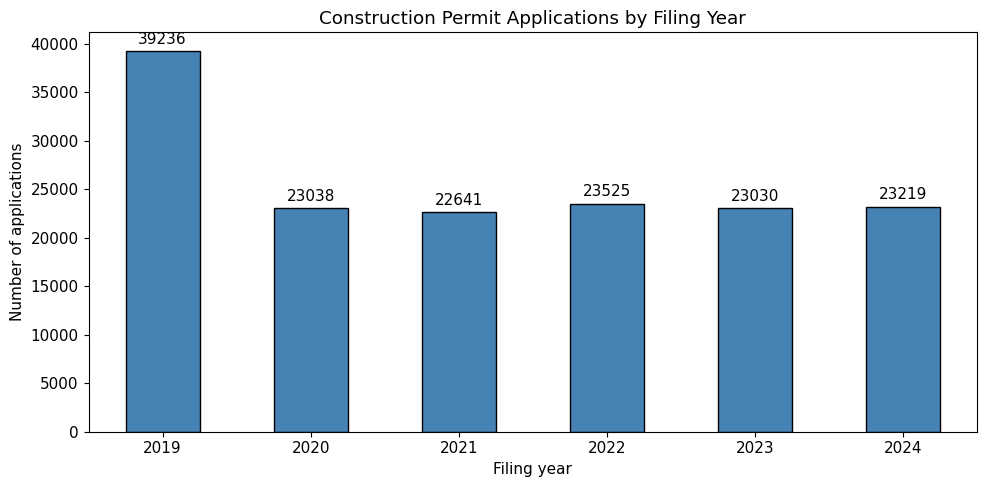

Yearly filing counts:


,applications
filing_year,
2019,39236
2020,23038
2021,22641
2022,23525
2023,23030
2024,23219


In [10]:
yearly_volume = clean.groupby('filing_year').size()
ax = yearly_volume.plot(kind='bar', color='steelblue', edgecolor='black')
ax.set(title='Construction Permit Applications by Filing Year',
       xlabel='Filing year', ylabel='Number of applications')
ax.bar_label(ax.containers[0], padding=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print('Yearly filing counts:')
display(yearly_volume.rename('applications').to_frame())

### Graph 1 — Result, insight and implication

**Result:** 2019 had the most filings (**39,236**), and 2021 the fewest (**22,641**). Filings fell from **39,236 in 2019** to **23,038 in 2020**, a **41.3% decrease**. From 2020–2024 annual filings stayed near 22,600–23,500.

**Insight:** Workload changed sharply after 2019, then stabilized. This graph describes filing activity, **not processing speed**.

**Practical implication:** Annual volume helps estimate staffing needs, but must be paired with issuance outcomes to judge performance.

**Viva:** “I used `groupby` and `size` to count applications filed in each year.”


## Graph 2 — Monthly application volume
**Question:** Are there peaks, dips or changing trends?

**Insight to write:** Identify the busiest and quietest months. Look for repeated seasonal patterns instead of assuming every peak indicates a bottleneck.

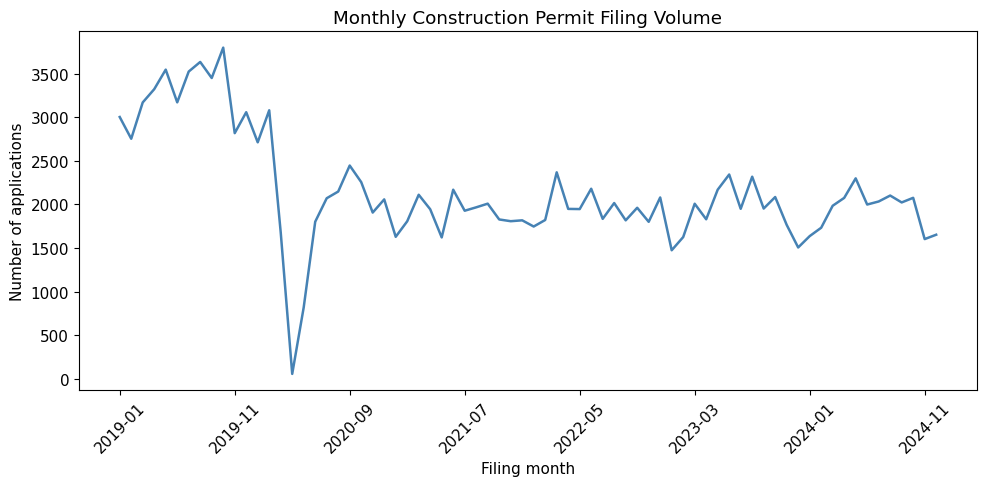

Busiest filing month: 2019-10 ( 3797 applications)
Quietest filing month: 2020-04 ( 58 applications)


In [11]:
monthly_volume = clean.groupby('filing_month').size().sort_index()
ax = monthly_volume.plot(color='steelblue', linewidth=1.8)
ax.set(title='Monthly Construction Permit Filing Volume',
       xlabel='Filing month', ylabel='Number of applications')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print('Busiest filing month:', monthly_volume.idxmax(), '(', monthly_volume.max(), 'applications)')
print('Quietest filing month:', monthly_volume.idxmin(), '(', monthly_volume.min(), 'applications)')

### Graph 2 — Result, insight and implication

**Result:** **October 2019** was the busiest filing month (**3,797 applications**); **April 2020** was the quietest (**58 applications**).

**Insight:** Monthly workload fluctuates substantially. April 2020 is an unusual low-volume observation that warrants contextual investigation; this dataset alone does not prove its cause.

**Practical implication:** Monthly monitoring can highlight unusual peaks and dips for workload planning.

**Viva:** “The line graph preserves the chronological order of filing months, making unusual changes visible.”


## Graph 3 — 365-day issuance rate by filing year
**Question:** What share of eligible applications filed each year were issued within 365 days?

**Insight to write:** Compare years carefully; rate is not the same as number issued. This is a filing-cohort outcome, **not** permits issued during the calendar year.

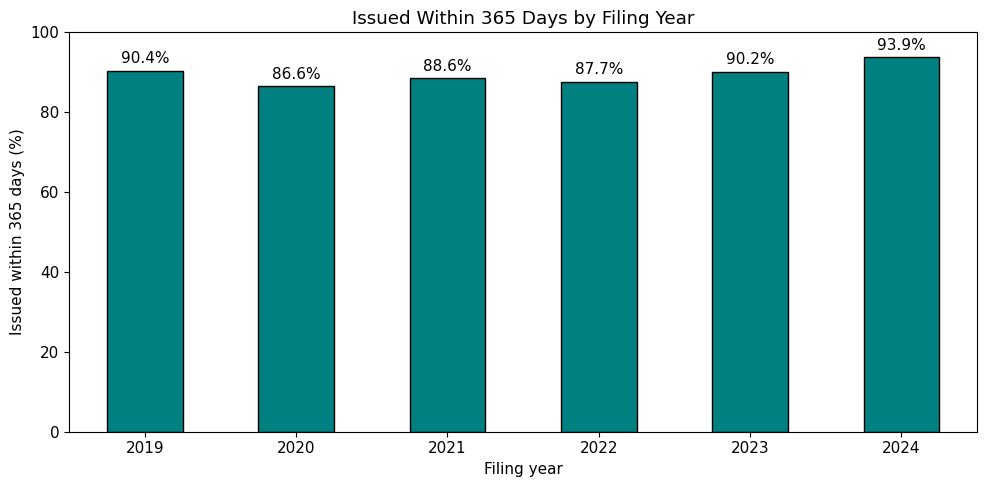

,eligible_applications,rate_percent
filing_year,,
2019,39234,90.421573
2020,23037,86.591136
2021,22640,88.643993
2022,23521,87.666341
2023,23024,90.171126
2024,23215,93.853112


In [12]:
yearly_rate = eda.groupby('filing_year')['issued_365_numeric'].agg(['size', 'mean'])
yearly_rate['rate_percent'] = yearly_rate['mean'] * 100
ax = yearly_rate['rate_percent'].plot(kind='bar', color='teal', edgecolor='black')
ax.set(title='Issued Within 365 Days by Filing Year',
       xlabel='Filing year', ylabel='Issued within 365 days (%)', ylim=(0, 100))
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(yearly_rate[['size', 'rate_percent']].rename(columns={'size': 'eligible_applications'}))

### Graph 3 — Result, insight and implication

**Result:** Yearly 365-day issuance rates: **2019: 90.42%**, **2020: 86.59%**, **2021: 88.64%**, **2022: 87.67%**, **2023: 90.17%**, **2024: 93.85%**. The lowest year was **2020**; the highest was **2024**.

**Insight:** Filing volume dropped from 2019 to 2020, yet the timely issuance rate also fell. Fewer applications did not automatically correspond to a higher issuance rate.

**Practical implication:** Track workload and timely issuance as **separate KPIs**.

**Viva:** “For each filing-year cohort, I calculated the mean of a 0/1 issued-within-365-days flag, which gives the percentage.”


## 9. Create the monthly analysis table
The **monthly volume** uses all applications filed that month. The **365-day rate** uses only eligible, known-outcome records filed that month. This makes the denominator transparent.

In [13]:
monthly_rate = eda.groupby('filing_month')['issued_365_numeric'].agg(
    eligible_applications='size', issued_within_365='sum', issuance_rate='mean'
)
monthly = monthly_volume.rename('applications_filed').to_frame().join(monthly_rate)
monthly['issuance_rate_percent'] = monthly['issuance_rate'] * 100
monthly['filing_year'] = pd.to_datetime(monthly.index).year
monthly.to_csv('monthly_application_eda.csv')
display(monthly.head(12))
print('Months:', len(monthly))
print('Any month with no eligible records:', monthly['issuance_rate'].isna().sum())

,applications_filed,eligible_applications,issued_within_365,issuance_rate,issuance_rate_percent,filing_year
filing_month,,,,,,
2019-01,3002,3002,2785,0.927715,92.771486,2019
2019-02,2753,2752,2545,0.924782,92.478198,2019
2019-03,3169,3169,2903,0.916062,91.606185,2019
2019-04,3321,3320,3025,0.911145,91.114458,2019
2019-05,3545,3545,3200,0.902680,90.267983,2019
2019-06,3170,3170,2886,0.910410,91.041009,2019
2019-07,3523,3523,3240,0.919671,91.967074,2019
2019-08,3633,3633,3323,0.914671,91.467107,2019
2019-09,3449,3449,3191,0.925196,92.519571,2019


Months: 72
Any month with no eligible records: 0


### Monthly aggregation — how to read this table

Each row represents a **filing month**. `applications_filed` counts all filings; `eligible_applications` counts only records with a valid observed 365-day outcome; `issued_within_365` counts successful outcomes. The **issuance rate** is `issued_within_365 / eligible_applications`.

**Insight:** There are **72 filing months** and none has an empty eligible denominator. The distinction between volume and eligible outcome counts is necessary to avoid treating invalid or unknown outcomes as failures.


## Graph 4 — Monthly 365-day issuance rate
**Question:** Does timely issuance change over filing months?

**Insight to write:** Locate low/high rate months and compare them with Graph 2. Avoid treating fluctuations as causal evidence.

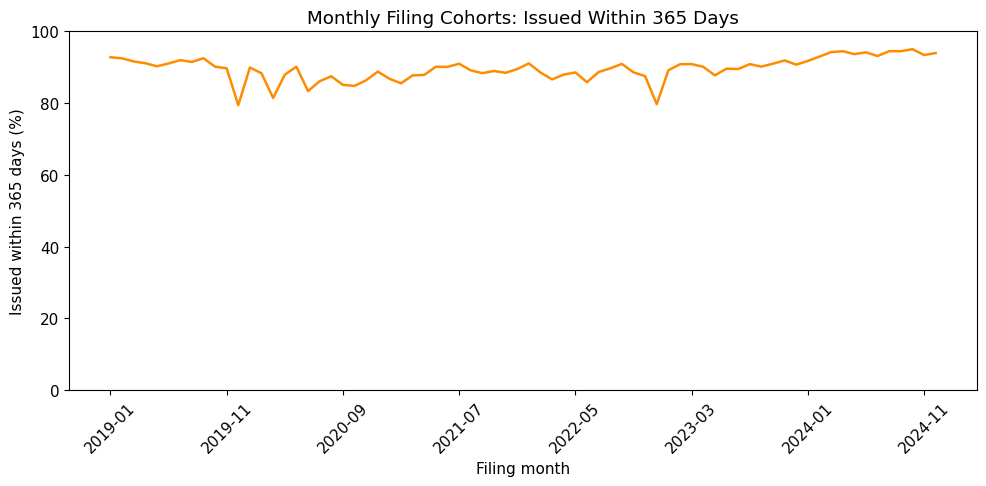

Lowest rate month: 2019-12 79.42 %
Highest rate month: 2024-10 95.04 %


In [14]:
ax = monthly['issuance_rate_percent'].plot(color='darkorange', linewidth=1.8)
ax.set(title='Monthly Filing Cohorts: Issued Within 365 Days',
       xlabel='Filing month', ylabel='Issued within 365 days (%)', ylim=(0, 100))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print('Lowest rate month:', monthly['issuance_rate_percent'].idxmin(),
      round(monthly['issuance_rate_percent'].min(), 2), '%')
print('Highest rate month:', monthly['issuance_rate_percent'].idxmax(),
      round(monthly['issuance_rate_percent'].max(), 2), '%')

### Graph 4 — Result, insight and implication

**Result:** The lowest monthly 365-day issuance rate was **79.42% (December 2019)**, and the highest was **95.04% (October 2024)**: a difference of **15.62 percentage points**.

**Insight:** Timely issuance varies by filing month. This alone does not identify the reason: permit mix, year-specific conditions and other factors may matter.

**Practical implication:** Teams can flag months with relatively low rates for further investigation.

**Viva:** “The monthly line chart helps spot changes in performance over time, but it cannot establish causality.”


## Graph 5 — Application volume vs 365-day issuance rate
**Question:** Do busier filing months appear to have lower issuance rates?

This is **exploratory only**. We will test statistical significance separately. Each dot represents one filing month.

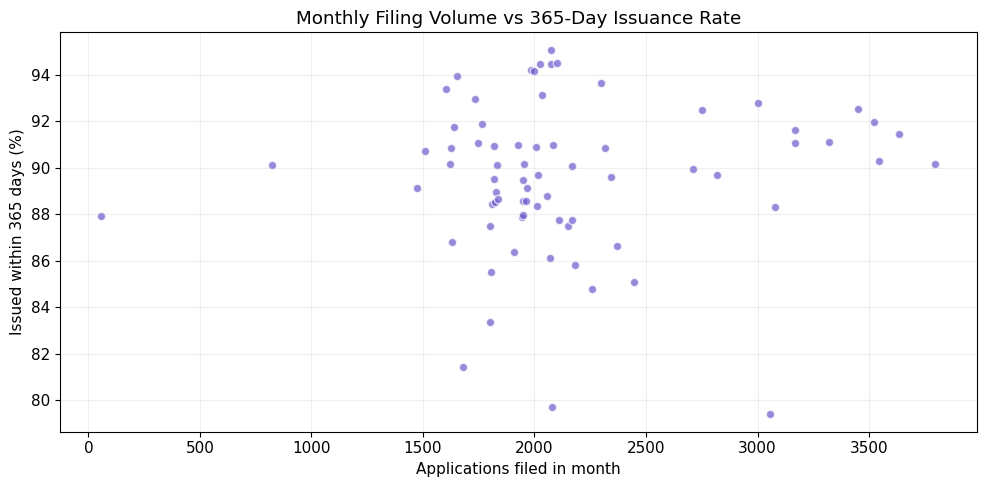

Visual interpretation: Is there a clear upward/downward pattern or mostly scatter?


In [15]:
plt.scatter(monthly['applications_filed'], monthly['issuance_rate_percent'],
            color='slateblue', alpha=0.7, edgecolors='white')
plt.title('Monthly Filing Volume vs 365-Day Issuance Rate')
plt.xlabel('Applications filed in month')
plt.ylabel('Issued within 365 days (%)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Visual interpretation: Is there a clear upward/downward pattern or mostly scatter?')

### Graph 5 — Result, insight and implication (main research question)

**Result:** The monthly scatter plot does **not show a clear downward pattern** between applications filed and the share issued within 365 days.

**Insight:** The visual evidence does not strongly support the prediction that busier filing months have lower issuance rates. A scatter plot is **descriptive**: no statistical significance claim is made here.

**Practical implication:** Investigate filing-year and permit-type differences before attributing slower issuance to volume alone.

**Viva:** “Each dot represents one month: x is applications filed, and y is the eligible cohort's 365-day issuance percentage.”


## Graph 6 — Compare quieter and busier filing months
Split months into **three approximately equal-sized groups by ranked volume**. Report group sizes and calculate the **application-weighted issuance rate**, so small and large months are not given identical weight. This is descriptive, not a hypothesis test.

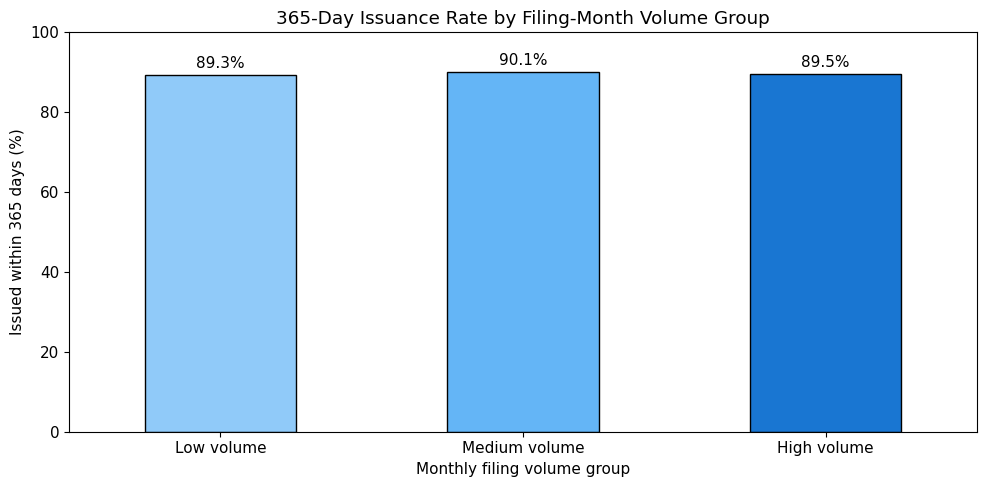

,months,average_monthly_volume,eligible_applications,issued_within_365,issuance_rate_percent
volume_group,,,,,
Low volume,24,1613.58,38718,34580,89.31
Medium volume,24,2010.00,48233,43439,90.06
High volume,24,2821.79,67720,60643,89.55


In [16]:
comparison = monthly.dropna(subset=['issuance_rate']).copy()
comparison['volume_group'] = pd.qcut(
    comparison['applications_filed'].rank(method='first'), 3,
    labels=['Low volume', 'Medium volume', 'High volume']
)
summary = comparison.groupby('volume_group', observed=True).agg(
    months=('applications_filed', 'size'),
    average_monthly_volume=('applications_filed', 'mean'),
    eligible_applications=('eligible_applications', 'sum'),
    issued_within_365=('issued_within_365', 'sum')
)
summary['issuance_rate_percent'] = (summary['issued_within_365'] /
                                     summary['eligible_applications'] * 100)
ax = summary['issuance_rate_percent'].plot(kind='bar', color=['#90caf9', '#64b5f6', '#1976d2'], edgecolor='black')
ax.set(title='365-Day Issuance Rate by Filing-Month Volume Group',
       xlabel='Monthly filing volume group', ylabel='Issued within 365 days (%)', ylim=(0, 100))
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(summary.round(2))

### Graph 6 — Result, insight and implication

| Filing-month group | Months | Average monthly filings | 365-day issuance rate |
|---|---:|---:|---:|
| Low volume | 24 | 1,613.58 | 89.31% |
| Medium volume | 24 | 2,010.00 | 90.06% |
| High volume | 24 | 2,821.79 | 89.55% |

**Result:** The high-volume group has an issuance rate just **0.24 percentage points higher** than the low-volume group, despite higher average filings.

**Insight:** Issuance rates are similar across the three groups; they do **not** decrease consistently as volume increases.

**Practical implication:** Workload alone may not be an adequate measure of issuance performance.

**Method note:** These percentages are **application-weighted** rates (successful eligible applications divided by all eligible applications in each group), not unweighted averages of the 24 monthly rates.

**Viva:** “I used `qcut` to create three equally sized groups of filing months, then compared their outcome rates.”


## 10. Additional simple EDA — permit mix and yearly context
Permit types may vary by month or year. A workload comparison can be misleading if the mix of application types changes. This table helps us flag that limitation.

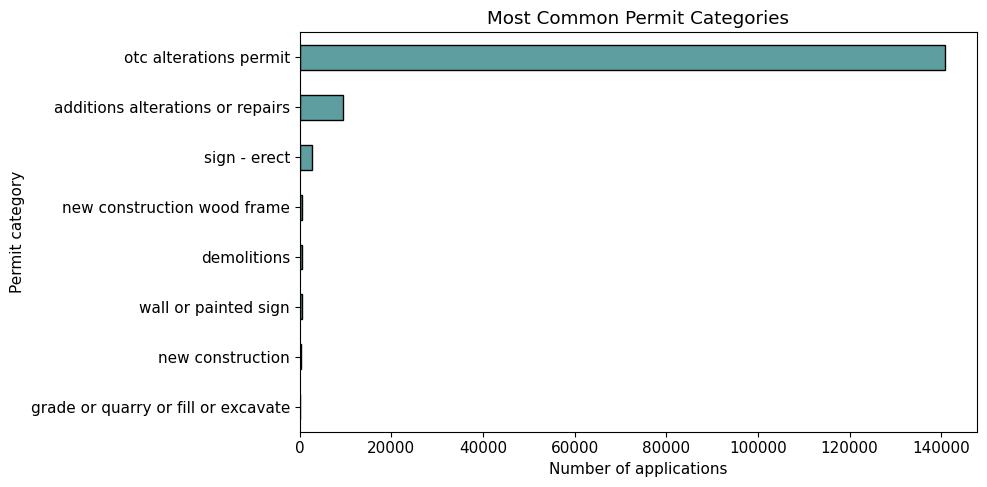

Applications by year and top permit categories:


permit_type_definition,otc alterations permit,additions alterations or repairs,sign - erect,new construction wood frame,demolitions,wall or painted sign,new construction,grade or quarry or fill or excavate
filing_year,,,,,,,,
2019,35727,2444,569,124,141,76,152,3
2020,20591,1796,416,61,84,53,21,16
2021,20393,1470,427,102,103,85,46,15
2022,21164,1665,316,150,95,78,47,10
2023,21264,1265,307,61,43,71,14,5
2024,21604,889,631,15,14,53,11,2


In [17]:
top_types = clean['permit_type_definition'].fillna('Unknown').value_counts().head(8)
ax = top_types.sort_values().plot(kind='barh', color='cadetblue', edgecolor='black')
ax.set(title='Most Common Permit Categories', xlabel='Number of applications', ylabel='Permit category')
plt.tight_layout()
plt.show()

print('Applications by year and top permit categories:')
top_names = top_types.index.tolist()
permit_mix = pd.crosstab(clean['filing_year'], clean['permit_type_definition'])
display(permit_mix.reindex(columns=top_names, fill_value=0))

### Permit mix — Result, insight and implication

**Result:** `otc alterations permit` is the dominant permit category. In **2019**, it accounted for **35,727 of 39,236 applications (~91.1%)**.

**Insight:** Overall filing trends may be heavily influenced by this category; a pooled volume-versus-rate comparison might mask different patterns in smaller categories.

**Practical implication:** A later analysis should repeat comparisons within important permit categories and filing years.

**Viva:** “A category distribution graph checks whether one permit type dominates our overall results.”


## 11. Data quality and cleaning summary
This is useful for the report and viva. The master CSV retains all valid unique records; the EDA subset applies additional restrictions only for the 365-day outcome.

In [18]:
audit = pd.DataFrame({
    'Check': ['Original records', 'Duplicate record IDs removed',
              'Missing filing dates in cleaned master',
              'Missing issuance dates in cleaned master',
              'Invalid issuance chronology flagged',
              'Ineligible/unknown 365-day outcomes',
              'Eligible records for issuance-rate EDA',
              'Filing months analysed'],
    'Value': [len(df), len(df) - len(clean), clean['filed_date'].isna().sum(),
              clean['issued_date'].isna().sum(),
              is_true(clean['invalid_issuance_chronology']).sum(),
              len(clean) - len(eda), len(eda), len(monthly)]
})
display(audit)
audit.to_csv('cleaning_audit.csv', index=False)

,Check,Value
0,Original records,154689
1,Duplicate record IDs removed,0
2,Missing filing dates in cleaned master,0
3,Missing issuance dates in cleaned master,11471
4,Invalid issuance chronology flagged,18
5,Ineligible/unknown 365-day outcomes,18
6,Eligible records for issuance-rate EDA,154671
7,Filing months analysed,72


### Cleaning audit — final interpretation

The audit confirms **0 duplicate record IDs removed**, **0 missing filing dates**, **11,471 missing issuance dates**, **18 invalid chronology flags**, and **154,671 valid outcome records** across **72 filing months**. The master data retains all rows; the EDA uses outcome-specific filtering. **No unusually long timelines were removed simply for being large.**


## Overall EDA conclusion — Hypothesis 4

**Research question:** Do filing months with more construction permit applications have a lower percentage issued within 365 days?

**Key findings:**

- The dataset includes **154,689 filings** from **2019–2024**, with **154,671 valid 365-day outcomes**.
- Filing volume fell sharply after 2019 and was relatively stable in 2020–2024.
- The overall 365-day issuance rate was **89.65%**. Yearly rates ranged from **86.59% (2020)** to **93.85% (2024)**.
- Monthly filing counts ranged from **58 (April 2020)** to **3,797 (October 2019)**.
- The scatter plot does not show a clear negative pattern, and the low-, medium-, and high-volume groups have similar issuance rates (**89.31%**, **90.06%**, **89.55%**).




## 13. Download outputs
Run this cell in Colab to download the shared cleaned dataset, monthly EDA table, and audit. The original uploaded CSV is not modified.

In [19]:
from google.colab import files
for filename in ['construction_permits_cleaned_shared.csv', 'monthly_application_eda.csv', 'cleaning_audit.csv']:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>